# 00 - Kiểm toán dữ liệu thô

Mục tiêu: trả lời *dữ liệu thô có đủ dùng cho Phương án A không* và chốt phạm vi dự án **trước khi làm sạch**.
Chạy từ thư mục `notebooks/` hoặc thư mục gốc. Dữ liệu: `data/raw/*.jsonl.gz` (hoặc đổi `SOURCE = "db"`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.raw_audit import audit_records, evaluate_checks, iter_payloads, iter_db, VALID_GRADES

SOURCE = "file"   # "file" hoặc "db"
PATTERN = str(ROOT / "data" / "raw" / "*.jsonl.gz")

In [2]:
payloads = iter_payloads(PATTERN) if SOURCE == "file" else iter_db()
summary = audit_records(payloads)
checks = evaluate_checks(summary)   # chỉnh min_usable, min_class... nếu cần
print(f"Tổng {summary['total']} | có nhãn {summary['labeled']} | dùng được {summary['usable']}")

Tổng 30000 | có nhãn 29998 | dùng được 29998


## 1. Các kiểm tra (OK / WARN / FAIL / INFO)

In [3]:
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(checks)

,name,status,detail
0,Có dữ liệu,OK,30000 bản ghi
1,Trùng mã vạch,OK,0 bản ghi trùng mã (xử lý ở bước cleaning)
2,Số bản ghi dùng được (nhãn hợp lệ + có thành phần),OK,"29998 bản ghi, mục tiêu tối thiểu 10000"
3,Mỗi hạng A-E đủ mẫu,OK,"hạng ít nhất có 3309 mẫu, ngưỡng 100"
4,Độ phủ NOVA,OK,90.3% bản ghi dùng được có nova_group hợp lệ (ngưỡng 50%)
5,Thẻ thành phần đã chuẩn hóa taxonomy (tiền tố en:),OK,94.8% thẻ có tiền tố en: (ngưỡng 90%)
6,Mức tập trung thương hiệu,WARN,"thương hiệu lớn nhất chiếm 14.9% (ngưỡng 10%), ảnh hưởng GroupKFold"
7,Mức tập trung quốc gia,INFO,quốc gia lớn nhất chiếm 37.8% bản ghi dùng được
8,Không thu thập trường cá nhân,OK,không có
9,Trường rò rỉ nhãn có trong dữ liệu thô,INFO,"nutriments, nutriscore_grade, nutriscore_score -> phải loại ở bước staging, không đưa vào đặc trưng"


## 2. Phân bố nhãn gốc, kể cả giá trị lạ

In [4]:
raw = pd.DataFrame(summary["grade_raw"], columns=["giá trị", "số bản ghi"])
raw

,giá trị,số bản ghi
0,e,8519
1,d,7128
2,c,6502
3,a,4540
4,b,3309
5,(thiếu),2


## 3. Phân bố hạng A-E: có nhãn so với dùng được

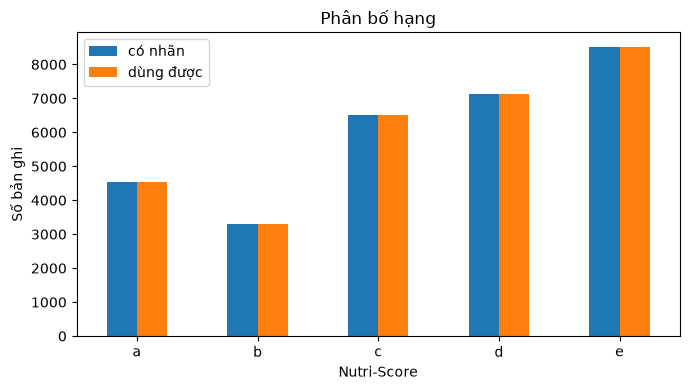

,có nhãn,dùng được
a,4540,4540
b,3309,3309
c,6502,6502
d,7128,7128
e,8519,8519


In [5]:
grades = pd.DataFrame({
    "có nhãn": summary["labeled_grades"],
    "dùng được": summary["usable_grades"],
}).loc[list(VALID_GRADES)]
ax = grades.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_xlabel("Nutri-Score"); ax.set_ylabel("Số bản ghi"); ax.set_title("Phân bố hạng")
plt.tight_layout(); plt.show()
grades

## 4. Quốc gia và thương hiệu (bản ghi dùng được)

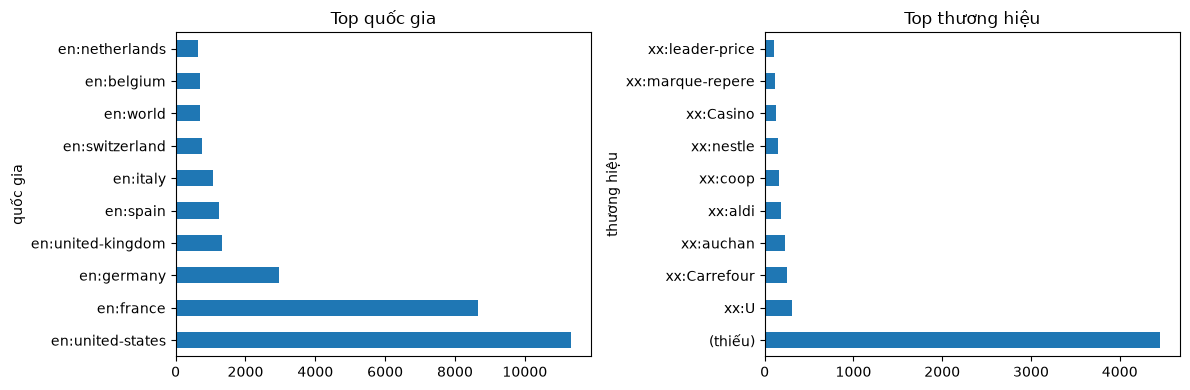

Thương hiệu lớn nhất chiếm 14.9% bản ghi dùng được


In [6]:
countries = pd.DataFrame(summary["countries_usable"], columns=["quốc gia", "số bản ghi"])
brands = pd.DataFrame(summary["brands"]["top"], columns=["thương hiệu", "số bản ghi"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if len(countries): countries.head(10).plot(kind="barh", x="quốc gia", y="số bản ghi", ax=axes[0], legend=False)
if len(brands): brands.head(10).plot(kind="barh", x="thương hiệu", y="số bản ghi", ax=axes[1], legend=False)
axes[0].set_title("Top quốc gia"); axes[1].set_title("Top thương hiệu")
plt.tight_layout(); plt.show()
print(f"Thương hiệu lớn nhất chiếm {100 * summary['brands']['top_share']:.1f}% bản ghi dùng được")

## 5. Tỷ lệ thiếu theo trường

In [7]:
fields = pd.DataFrame(summary["fields"]).T
total, labeled = max(summary["total"], 1), max(summary["labeled"], 1)
missing = pd.DataFrame({
    "vắng mặt (%)": 100 * fields["absent_all"] / total,
    "vắng hoặc rỗng (%)": 100 * fields["missing_all"] / total,
    "vắng hoặc rỗng, có nhãn (%)": 100 * fields["missing_labeled"] / labeled,
}).round(1).sort_values("vắng hoặc rỗng (%)", ascending=False)
missing

,vắng mặt (%),vắng hoặc rỗng (%),"vắng hoặc rỗng, có nhãn (%)"
labels_tags,39.6,55.2,55.2
additives_tags,0.0,44.1,44.1
allergens_tags,0.0,38.6,38.6
pnns_groups_2,20.4,20.4,20.4
pnns_groups_1,19.9,19.9,19.9
brands_tags,13.1,14.9,14.9
nova_group,9.7,9.7,9.7
product_name,0.7,0.7,0.7
nutriments,0.0,0.5,0.5
countries_tags,0.0,0.3,0.3


## 6. Hạng theo NOVA

In [8]:
pd.DataFrame(summary["grade_by_nova"]).T.loc[list(VALID_GRADES)]

,1,2,3,4
a,1905,13,934,1152
b,639,114,682,1274
c,517,83,1367,4010
d,271,39,1723,4607
e,106,209,1199,6234


## 7. Trường rò rỉ nhãn, trường cá nhân, trường Nutri-Score

In [9]:
print("Rò rỉ nhãn (phải loại ở staging):", summary["leakage_fields_present"])
print("Cá nhân (phải rỗng):", summary["pii_fields_present"])
print("Liên quan Nutri-Score (xem có trường phiên bản công thức không):", summary["nutriscore_related_fields"])

Rò rỉ nhãn (phải loại ở staging): ['nutriments', 'nutriscore_grade', 'nutriscore_score']
Cá nhân (phải rỗng): []
Liên quan Nutri-Score (xem có trường phiên bản công thức không): ['nutriscore_grade', 'nutriscore_score']


## 8. Quyết định phạm vi

Điền kết luận vào `docs/scope_decision.md`: phạm vi quốc gia, nguồn dữ liệu (API hay dump), cách xử lý NOVA thiếu,
phiên bản công thức Nutri-Score, kèm các con số ở trên.